# 02 · ข้อ 1 วันธรรมดา vs วันหยุดสุดสัปดาห์
ผู้รับผิดชอบ: สมาชิก A · ต้องรัน `01_cleaning.ipynb` (หรือ `python src/run_all.py`) ก่อน

**คำถาม:** ปริมาณการใช้บริการขนส่งแตกต่างกันอย่างไรระหว่างวันธรรมดาและวันหยุดสุดสัปดาห์ ต่างกันอย่างไรในแต่ละวันของสัปดาห์ และรูปแบบนี้เปลี่ยนไปในแต่ละเดือนหรือไม่

โค้ดทั้งหมดอยู่ใน `src/q1_weekday.py` (ตรวจด้วย `pytest tests/test_q1_weekday.py`) notebook นี้มีหน้าที่**เรียกฟังก์ชันและแสดงผล**พร้อมคำอธิบาย

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import prep
import features
import plots

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
_ = plots.setup_style()
import q1_weekday

df = prep.load_clean()
print(df.shape)

(18705, 18)


## 1. Feature Selection

| Feature ต้นฉบับ | เหตุผล |
|---|---|
| `date` | สร้างวันในสัปดาห์และเดือน |
| `service`, `purpose`, `mode` | เปรียบเทียบรูปแบบระหว่างบริการ/กลุ่มการเดินทาง |
| `value` | จำนวนผู้ใช้บริการต่อวัน |
| `unit`, `exclude_reason`, `is_aggregate`, `missing_flag`, `zero_long_run` | ใช้กรอง (คนเท่านั้น, ไม่ใช่ยอดรวม, ไม่ใช่ช่วงหยุดรายงาน) |

## 2. Data Preparation

In [2]:
# ปี 2568 · หน่วย "คน" · ตัดค่าว่างและศูนย์ช่วงหยุดรายงาน (ไม่นับเป็น 0 เพื่อไม่ให้ค่าเฉลี่ยต่ำเกินจริง)
rows = q1_weekday.select_rows(df)
print(rows.shape, rows["service"].nunique(), "services")
print("แถวที่ตัดเพราะค่าว่าง/ศูนย์ช่วงยาว:", len(prep.passenger_rows(df).query("year_be == 2568")) - len(rows))
rows.groupby("purpose")["service"].nunique()

(13664, 18) 38 services
แถวที่ตัดเพราะค่าว่าง/ศูนย์ช่วงยาว: 206


purpose
intercity         9
international    14
intracity        15
Name: service, dtype: int64

## 3. Feature Engineering

| Feature ใหม่ | สร้างจาก | สูตร / เงื่อนไข | ประโยชน์ |
|---|---|---|---|
| `day_of_week`, `day_name_th`, `month` | `date` | `dayofweek` (0 = จันทร์), `month` | แกนจัดกลุ่ม |
| `is_weekend` | `day_of_week` | `day_of_week ∈ {5, 6}` | แบ่งกลุ่มหลักตามโจทย์ |
| `dow_index` | `value`, `service` | `value / mean(value ของบริการนั้นทั้งปี) × 100` | เทียบบริการที่ขนาดต่างกันหลายร้อยเท่าบนสเกลเดียว |
| `weekend_ratio` | `value`, `is_weekend` | `mean(เสาร์–อาทิตย์) / mean(จันทร์–ศุกร์)` ต่อบริการ (× เดือน) | ตัวชี้วัดเดียว: < 1 = การเดินทางไปทำงาน, > 1 = ท่องเที่ยว/กลับบ้าน |
| `pct_diff_weekend` | `weekend_ratio` | `(weekend_ratio − 1) × 100` | อ่านง่าย (“วันหยุดน้อยกว่า X%”) |

In [3]:
daily = q1_weekday.build_daily_features(rows)
daily[["date", "service", "value", "day_name_th", "is_weekend", "month", "dow_index"]].head()

,date,service,value,day_name_th,is_weekend,month,dow_index
0,2025-01-01,ท่าอากาศยานดอนเมือง,31842.0,พุธ,False,1,119.230276
1,2025-01-02,ท่าอากาศยานดอนเมือง,32333.0,พฤหัสบดี,False,1,121.068793
2,2025-01-03,ท่าอากาศยานดอนเมือง,34067.0,ศุกร์,False,1,127.561642
3,2025-01-04,ท่าอากาศยานดอนเมือง,34798.0,เสาร์,True,1,130.298823
4,2025-01-05,ท่าอากาศยานดอนเมือง,33342.0,อาทิตย์,True,1,124.846927


In [4]:
# ระดับบริการ: weekend_ratio ทั้งปี เรียงจากน้อยไปมาก
by_service = q1_weekday.weekend_ratio_table(daily, by=("purpose", "service"))
by_service.sort_values("weekend_ratio").round(3)

,purpose,service,weekday_mean,weekend_mean,weekend_ratio,pct_diff_weekend
34,intracity,เรือคลองแสนแสบ,20680.912,7039.788,0.340,-65.960
35,intracity,เรือด่วนเจ้าพระยา,11596.808,5430.077,0.468,-53.176
30,intracity,รถไฟฟ้าสายสีม่วง,77888.131,43124.721,0.554,-44.632
29,intracity,รถไฟฟ้าสายสีน้ำเงิน,472724.062,303882.452,0.643,-35.717
28,intracity,รถไฟฟ้าสายสีชมพู,68508.927,44391.577,0.648,-35.203
32,intracity,รถไฟฟ้าสายสีแดง,39633.506,27733.933,0.700,-30.024
27,intracity,รถไฟฟ้า BTS,789712.429,556517.673,0.705,-29.529
31,intracity,รถไฟฟ้าสายสีเหลือง,49289.696,35416.779,0.719,-28.146
26,intracity,รถไฟฟ้า ARL,69868.927,52244.096,0.748,-25.226
25,intracity,รถเอกชนเส้นปฏิรูป (หมวด 1),353528.318,274548.529,0.777,-22.340


In [5]:
# สรุปต่อกลุ่มการเดินทาง (นับทุกบริการเท่ากัน)
by_service.groupby("purpose")["weekend_ratio"].agg(["min", "median", "max", "count"]).round(3)

,min,median,max,count
purpose,,,,
intercity,0.849,1.031,1.145,9
international,1.016,1.062,1.384,14
intracity,0.340,0.719,1.100,15


In [6]:
# ระดับบริการ × เดือน (ใช้ทำกราฟรายเดือน)
by_month = q1_weekday.weekend_ratio_table(daily, by=("purpose", "service", "month"))
by_month.groupby(["purpose", "month"])["weekend_ratio"].mean().unstack("month").round(3)

month,1,2,3,4,5,6,7,8,9,10,11,12
purpose,,,,,,,,,,,,
intercity,1.014,1.037,1.033,1.112,1.003,1.000,1.046,0.980,1.008,1.037,1.017,1.090
international,1.029,1.055,1.110,1.079,1.123,1.132,1.149,1.121,1.100,1.111,1.106,1.057
intracity,0.741,0.755,0.741,0.764,0.752,0.734,0.738,0.728,0.698,0.739,0.716,0.745


## 4. Visualization

### กราฟที่ 1: ดัชนีวันในสัปดาห์ แยกตามกลุ่มการเดินทาง (line chart)

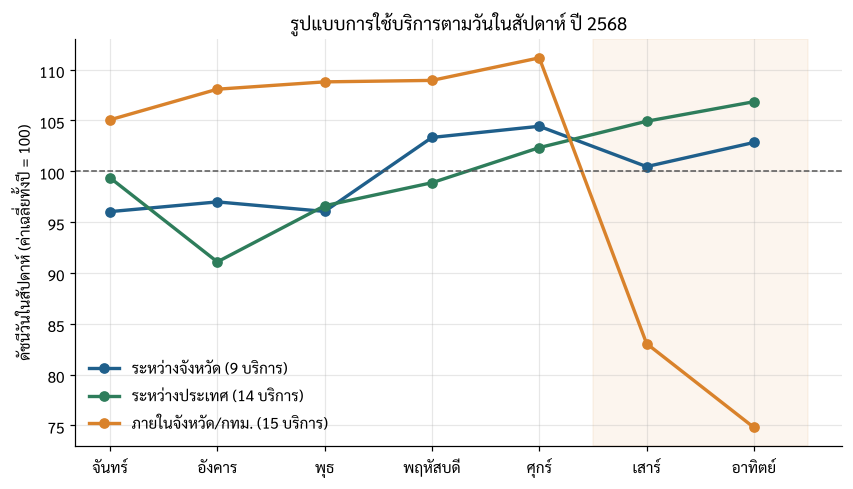

In [7]:
fig = q1_weekday.plot_dow_index(daily)
plots.save_fig(fig, "q1_dow_index"); plt.show()

> ✍️ **ร่างการตีความ** เขียนจากผลที่รันจริง ทีมต้องอ่านทวนและปรับให้เป็นคำของตัวเองก่อนใส่รายงาน

เลือก line chart เพราะแกน x เป็นลำดับวันที่ต่อเนื่อง (จันทร์→อาทิตย์) เส้นแสดงรูปทรงของสัปดาห์ได้ชัดกว่าแท่ง และใช้ดัชนีแทนจำนวนจริง เพื่อให้บริการขนาดต่างกันเทียบกันได้
- **ภายในจังหวัด/กทม.** ดัชนีวันธรรมดาอยู่ราว 105–111 (สูงสุดวันศุกร์ 111.2) แล้วลดลงเหลือ 83.0 วันเสาร์ และ 74.8 วันอาทิตย์ เป็นรูปแบบของการเดินทางไปทำงาน/เรียน
- **ระหว่างจังหวัด** และ **ระหว่างประเทศ** มีรูปแบบกลับกัน คือสูงช่วงปลายสัปดาห์ ระหว่างจังหวัดต่ำช่วงจันทร์–พุธ (96–97) และสูงช่วงพฤหัส–ศุกร์ (103.3, 104.4) กับวันอาทิตย์ (102.8) สอดคล้องกับการเดินทางออกต่างจังหวัดก่อนวันหยุดและกลับวันอาทิตย์ ระหว่างประเทศสูงสุดวันอาทิตย์ (106.8)

### กราฟที่ 2: Heatmap เดือน × วันในสัปดาห์

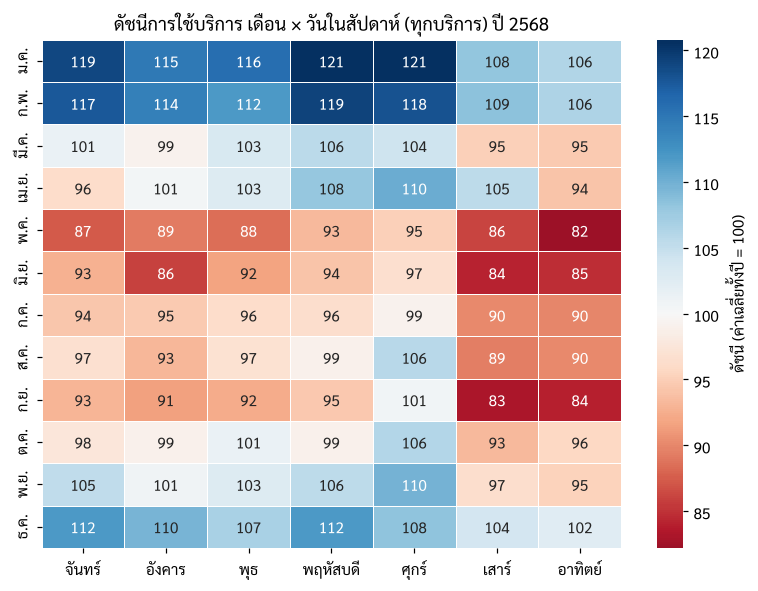

In [8]:
fig = q1_weekday.plot_month_dow_heatmap(daily)
plots.save_fig(fig, "q1_month_dow_heatmap"); plt.show()

> ✍️ **ร่างการตีความ** เขียนจากผลที่รันจริง ทีมต้องอ่านทวนและปรับให้เป็นคำของตัวเองก่อนใส่รายงาน

เลือก heatmap เพราะต้องดู 2 มิติพร้อมกัน (เดือน และวันในสัปดาห์) ตัวเลขในช่องช่วยให้อ่านค่าได้ตรง
- เกือบทุกเดือน ช่องเสาร์–อาทิตย์มีค่าต่ำกว่าวันธรรมดาของเดือนเดียวกัน (ภาพรวมทุกบริการ ซึ่งกลุ่มในเมืองมีจำนวนบริการมากที่สุด)
- มีผลของฤดูกาลซ้อนอยู่ด้วย: ม.ค.–ก.พ. และ ธ.ค. สูงกว่าค่าเฉลี่ย (106–121) ส่วน พ.ค.–ก.ย. ส่วนใหญ่ต่ำกว่า 100 (ต่ำสุด 82) ยกเว้นวันศุกร์บางเดือน

### กราฟที่ 3: weekend ratio รายเดือน

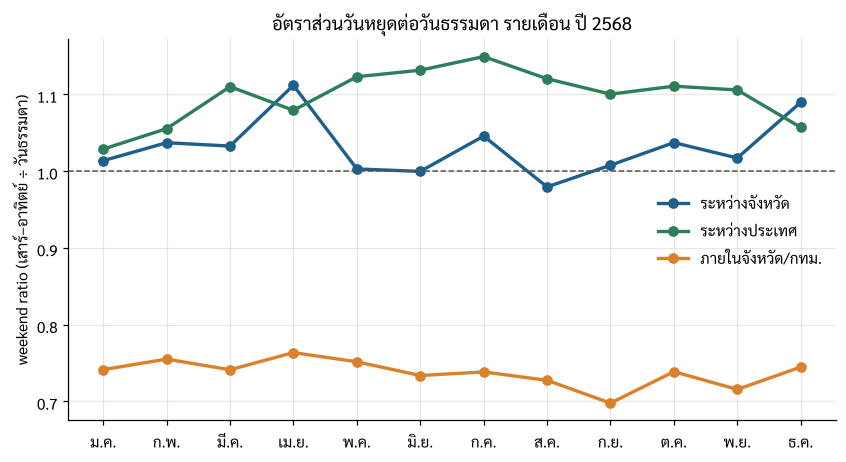

In [9]:
fig = q1_weekday.plot_weekend_ratio_monthly(by_month)
plots.save_fig(fig, "q1_weekend_ratio_monthly"); plt.show()

> ✍️ **ร่างการตีความ** เขียนจากผลที่รันจริง ทีมต้องอ่านทวนและปรับให้เป็นคำของตัวเองก่อนใส่รายงาน

ตอบคำถามส่วน “รูปแบบเปลี่ยนไปในแต่ละเดือนหรือไม่” โดยตรง เส้นอ้างอิง 1.0 คือวันหยุดเท่ากับวันธรรมดา
- **ภายในจังหวัด/กทม.** อยู่ต่ำกว่า 1 ทุกเดือนและค่อนข้างคงที่ (0.70–0.76) ต่ำสุด ก.ย. (0.698)
- **ระหว่างจังหวัด** ใกล้ 1 เกือบทั้งปี แต่สูงขึ้นชัดใน เม.ย. (1.112, ช่วงสงกรานต์) และ ธ.ค. (1.090, ช่วงปีใหม่)
- **ระหว่างประเทศ** สูงกว่า 1 ทุกเดือน (1.03–1.15)

## 5. Analysis & Findings
> ✍️ **ร่างการตีความ** เขียนจากผลที่รันจริง ทีมต้องอ่านทวนและปรับให้เป็นคำของตัวเองก่อนใส่รายงาน

**คำตอบ:** ความแตกต่างระหว่างวันธรรมดากับวันหยุดขึ้นกับวัตถุประสงค์ของการเดินทาง
1. **การเดินทางในเมือง** ลดลงชัดเจนในวันหยุด 13 จาก 15 บริการมี weekend ratio < 1 (ค่ากลาง 0.719) ลดมากที่สุดคือเรือคลองแสนแสบ (−66%), เรือด่วนเจ้าพระยา (−53%), รถไฟฟ้าสายสีม่วง (−45%) ส่วน BTS ลดประมาณ 30% และ ขสมก. ลดประมาณ 21% บริการที่ไม่ลดคือเรือภูมิภาค และเรือไฟฟ้าเจ้าพระยา (+10%) ซึ่งน่าจะเป็นการใช้เพื่อท่องเที่ยว
2. **ระหว่างจังหวัดและระหว่างประเทศ** เพิ่มขึ้นเล็กน้อยในวันหยุด (ค่ากลาง 1.031 และ 1.062) เช่น รถ บขส. และรถร่วม +14.5%, รถไฟระหว่างประเทศขาออก +38%
3. **รายเดือน:** รูปแบบของการเดินทางในเมืองคงที่ตลอดปี แต่การเดินทางระหว่างจังหวัดมีจุดพีคในวันหยุดช่วงเทศกาล (เม.ย., ธ.ค.)

**ข้อจำกัด**
- ยังไม่ได้แยกวันหยุดนักขัตฤกษ์ที่ตรงกับวันธรรมดา (เช่น สงกรานต์ 14–15 เม.ย. 2568 เป็นวันจันทร์–อังคาร) จึงถูกนับเป็นวันธรรมดา ทำให้ค่าเฉลี่ยวันธรรมดาของเดือนนั้นคลาดเคลื่อน
- ค่าเฉลี่ยของกลุ่มนับทุกบริการเท่ากัน บริการขนาดเล็กจึงมีน้ำหนักเท่าบริการขนาดใหญ่
- รถหมวด 3/4 มีข้อมูลถึง ก.ย. 2568 เท่านั้น

## 6. บันทึก Prepared Dataset

In [10]:
out = q1_weekday.output_table(daily)
out.to_csv(prep.PREPARED_DIR / q1_weekday.OUTPUT_FILE, index=False, encoding="utf-8-sig")
print(q1_weekday.OUTPUT_FILE, out.shape)

q1_daily_features.csv (13664, 12)
